# Segmentación de Clientes con K-Means — Mall Customers Dataset

**Objetivo general:** desarrollar un modelo de segmentación con K-Means, evaluado con el método del codo y la silueta, para analizar patrones y apoyar decisiones de marketing.

**Objetivos específicos:** comprender K-Means · aplicar StandardScaler · determinar el K óptimo · evaluar con métricas · interpretar el negocio · desplegar con Streamlit.

**Dataset:** Mall Customers (Kaggle, `vjchoudhary7/customer-segmentation-tutorial-in-python`), 200 filas × 5 columnas. Diccionario: `CustomerID` (identificador, se excluye del modelo), `Gender`, `Age`, `Annual Income (k$)` (miles de USD), `Spending Score (1-100)`.
**Modelo final:** KMeans K=5 (`random_state=42`, `n_init=10`) sobre `[Annual Income (k$), Spending Score (1-100)]` estandarizados. Silueta **0.5547**, inercia **65.57**.


In [ ]:
# Carga robusta: usa data/Mall_Customers.csv local si existe; si no, Kaggle (requiere internet).
import os, glob
import pandas as pd

candidatos = ['data/Mall_Customers.csv', '../data/Mall_Customers.csv']
archivo_csv = next((c for c in candidatos if os.path.exists(c)), None)
try:
    import kagglehub
    _tiene_kagglehub = True
except ImportError:
    _tiene_kagglehub = False

if archivo_csv is None and _tiene_kagglehub:
    path = kagglehub.dataset_download('vjchoudhary7/customer-segmentation-tutorial-in-python')
    hallados = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)
    if not hallados:
        raise FileNotFoundError('No se encontró ningún CSV.')
    archivo_csv = hallados[0]
if archivo_csv is None:
    raise FileNotFoundError('No se encontró data/Mall_Customers.csv y kagglehub no está disponible.')

df = pd.read_csv(archivo_csv)
print('Archivo cargado:', archivo_csv)
print('Dimensiones:', df.shape)
display(df.head())


## Parte 1 — Exploración de datos: respuestas

- **¿Qué variables son más adecuadas?** `Annual Income (k$)` y `Spending Score (1-100)`: son comportamentales (capacidad y propensión de gasto), casi incorrelacionadas (r≈0.01) y el scatter 2D muestra grupos naturales. `CustomerID` se excluye (identificador). `Age`/`Gender` se usan solo de forma descriptiva.
- **¿Atípicos?** Boxplots sin valores extremos inválidos; el ingreso máximo (137 k$) es alto pero plausible. 0 nulos, 0 duplicados.
- **¿Relaciones?** Edad–gasto r≈−0.33 (los jóvenes tienden a gastar más); edad–ingreso r≈−0.01 e ingreso–gasto r≈0.01 (sin asociación lineal). Correlación ≠ causalidad.


In [3]:
# Información general
print("Información del dataset:")
df.info()

# Estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df.describe(include="all"))

# Valores faltantes
print("\nValores faltantes por columna:")
print(df.isnull().sum())

# Registros duplicados
print("\nRegistros duplicados:", df.duplicated().sum())

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Estadísticas descriptivas:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000



Valores faltantes por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Registros duplicados: 0


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
print("Columnas disponibles:")
print(df.columns.tolist())

variables_numericas = df.select_dtypes(include=np.number)

print("\nVariables numéricas:")
print(variables_numericas.columns.tolist())

display(variables_numericas.head())

Columnas disponibles:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Variables numéricas:
['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,2,21,15,81
2,3,20,16,6
3,4,23,16,77
4,5,31,17,40


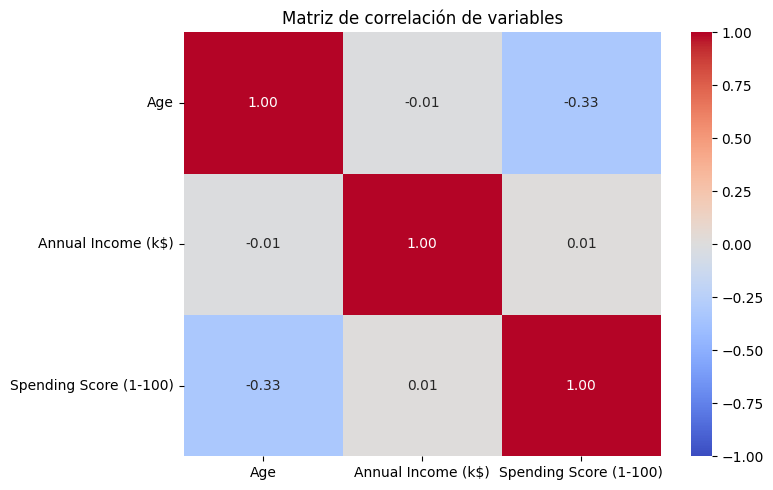

In [7]:
correlacion = variables_numericas.drop(
    columns=["CustomerID"]
).corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación de variables")
plt.tight_layout()
plt.show()

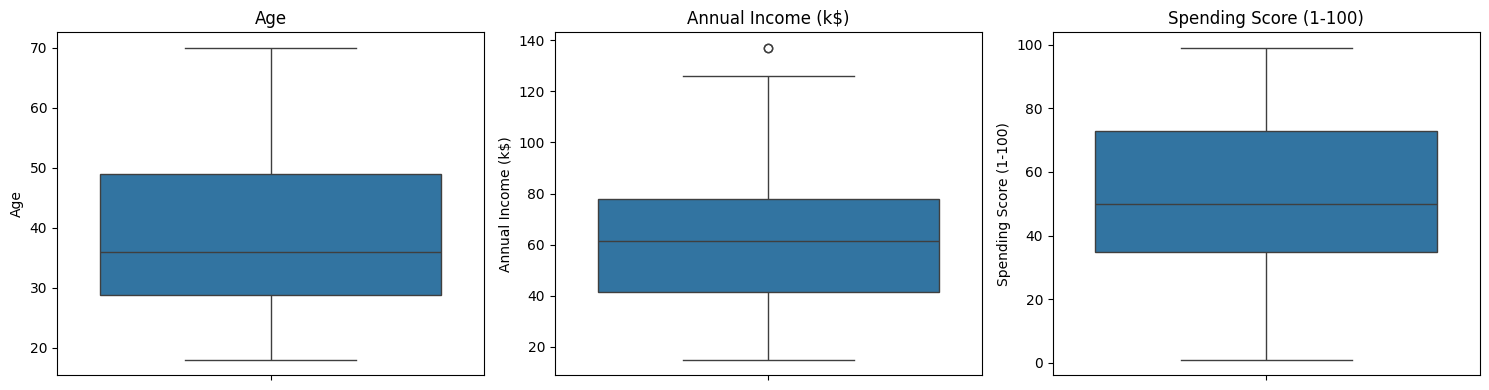

In [8]:
variables = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

plt.figure(figsize=(15, 4))

for i, columna in enumerate(variables, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[columna])
    plt.title(columna)

plt.tight_layout()
plt.show()

In [9]:
display(
    df[variables].describe().round(2)
)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


## Parte 2 — Preprocesamiento: respuesta

- **¿Por qué escalar en K-Means?** K-Means minimiza distancias euclidianas; sin escalar, la variable de mayor rango/magnitud dominaría la distancia y deformaría los clusters. `StandardScaler` (media 0, desv. 1) da igual peso a ingreso y gasto. En predicción se reutiliza el scaler guardado con `transform()` — nunca se reentrena con un cliente individual — y se respeta el orden de features.


In [10]:
from sklearn.preprocessing import StandardScaler

# Seleccionar ingresos y puntuación de gasto
X = df[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].copy()

# Estandarizar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dimensiones:", X_scaled.shape)
print("Medias:", X_scaled.mean(axis=0).round(4))
print("Desviaciones estándar:", X_scaled.std(axis=0).round(4))

display(pd.DataFrame(
    X_scaled,
    columns=X.columns
).head())

Dimensiones: (200, 2)
Medias: [-0. -0.]
Desviaciones estándar: [1. 1.]


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


## Parte 3 — Método del codo: respuestas

Inercias K=1…10: 400.00, 269.69, 157.70, 108.92, **65.57**, 55.06, 44.86, 37.23, 32.39, 29.98.

- **¿Por qué valores cercanos a cero indican mejor ajuste?** La inercia suma distancias cuadradas punto–centroide; cercana a 0 significa que cada punto casi coincide con su centroide (ajuste perfecto en entrenamiento, p. ej. K=n).
- **¿Cómo se identifica el K óptimo?** En el punto donde la curva se dobla (codo): la ganancia marginal cae. Aquí el codo está en **K=5** (de 108.92→65.57, luego solo →55.06). Limitación: es heurístico y visual; el K de menor inercia NO es automáticamente el mejor (sobreajuste).


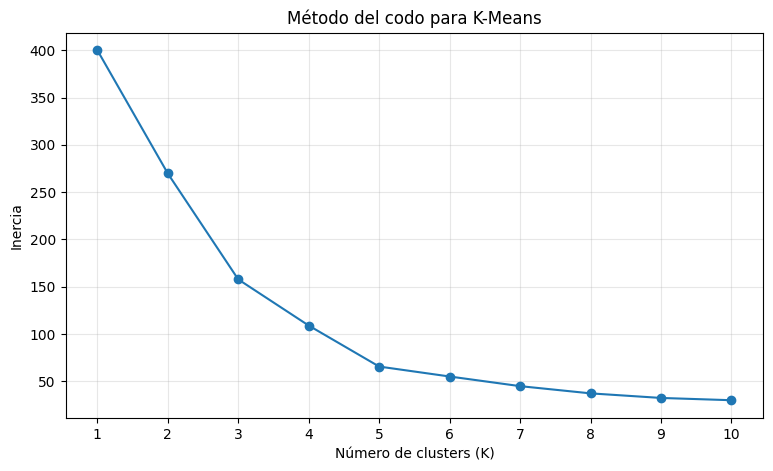

In [11]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Probar diferentes cantidades de clusters
inercias = []
valores_k = range(1, 11)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

# Graficar el método del codo
plt.figure(figsize=(9, 5))
plt.plot(valores_k, inercias, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo para K-Means")
plt.xticks(list(valores_k))
plt.grid(True, alpha=0.3)
plt.show()

## Parte 4 — Coeficiente de silueta: respuestas

Siluetas K=2…10: 0.3213, 0.4666, 0.4939, **0.5547**, 0.5399, 0.5281, 0.4552, 0.4571, 0.4432.

- **¿Qué mide?** Cohesión vs. separación por punto (qué tan parecido es a su cluster frente al vecino más cercano); se promedia.
- **¿Cercano a 1?** Punto bien asignado, cluster compacto y separado. **¿Cercano a 0?** En la frontera entre clusters. **¿Negativo?** Probablemente mal asignado.
- **¿Coincide con el codo?** Sí: el máximo (**0.5547 en K=5**) coincide con el codo. K final = **5** por convergencia de ambos criterios, simplicidad y utilidad de negocio (5 perfiles diferenciables).


K = 2: Silueta = 0.3213
K = 3: Silueta = 0.4666
K = 4: Silueta = 0.4939
K = 5: Silueta = 0.5547
K = 6: Silueta = 0.5399
K = 7: Silueta = 0.5281
K = 8: Silueta = 0.4552
K = 9: Silueta = 0.4571
K = 10: Silueta = 0.4432


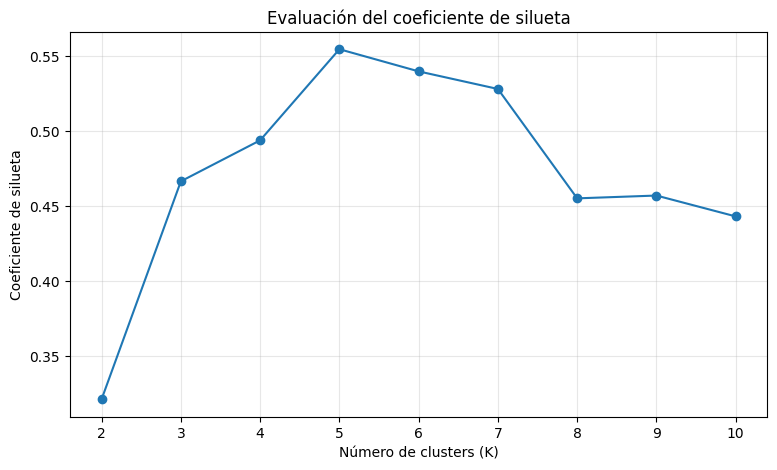

In [12]:
from sklearn.metrics import silhouette_score

resultados_silueta = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)
    puntuacion = silhouette_score(X_scaled, etiquetas)

    resultados_silueta.append((k, puntuacion))

for k, puntuacion in resultados_silueta:
    print(f"K = {k}: Silueta = {puntuacion:.4f}")

# Graficar los resultados
valores = [r[0] for r in resultados_silueta]
puntuaciones = [r[1] for r in resultados_silueta]

plt.figure(figsize=(9, 5))
plt.plot(valores, puntuaciones, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Coeficiente de silueta")
plt.title("Evaluación del coeficiente de silueta")
plt.xticks(valores)
plt.grid(True, alpha=0.3)
plt.show()

## Parte 5 — Modelo K-Means: respuestas

Tamaños: C0=81 (40.5 %), C1=39 (19.5 %), C2=22 (11 %), C3=35 (17.5 %), C4=23 (11.5 %). Centroides (ingreso k$, gasto): C0=(55.30, 49.52), C1=(86.54, 82.13), C2=(25.73, 79.36), C3=(88.20, 17.11), C4=(26.30, 20.91). Edades medias: 42.7, 32.7, 25.3, 41.1, 45.2.

- **¿Qué representa cada cluster?** C0 promedio; C1 alto valor; C2 jóvenes entusiastas (bajo ingreso/alto gasto); C3 cautelosos premium (alto ingreso/bajo gasto); C4 bajo valor. Los IDs numéricos son arbitrarios: no hay jerarquía entre ellos.
- **¿Diferencias?** El ingreso separa C1/C3 (altos) de C2/C4 (bajos); el gasto separa C1/C2 (altos) de C3/C4 (bajos); C0 queda en el centro. La edad distingue a C2 (jóvenes) de C4 (mayores).


In [13]:
K_ELEGIDO = 5  # Cambia este valor según tus resultados

kmeans = KMeans(
    n_clusters=K_ELEGIDO,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cantidad de clientes por cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nCentroides en las unidades originales:")

centroides = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns
)

display(centroides.round(2))

Cantidad de clientes por cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Centroides en las unidades originales:


,Annual Income (k$),Spending Score (1-100)
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


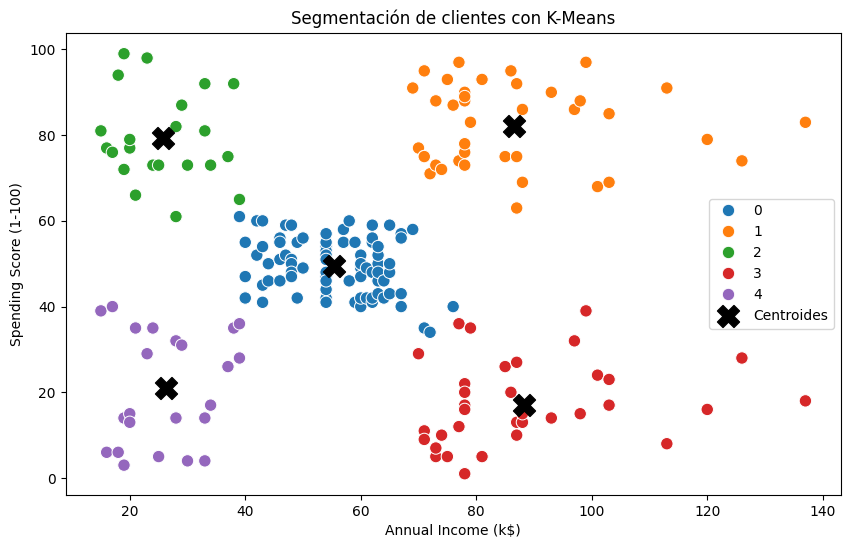

In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=80
)

centroides_grafica = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.scatter(
    centroides_grafica[:, 0],
    centroides_grafica[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroides"
)

plt.title("Segmentación de clientes con K-Means (K=5)")
plt.xlabel("Annual Income (k$) \u2014 miles de USD")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

## Parte 6 — Interpretación de negocio: respuestas

- **Estrategias:** C1 premium/exclusividad; C0 fidelización y venta cruzada; C2 facilidades de pago y marketing digital; C3 demostrar valor (garantías, asesoría) para desbloquear gasto; C4 ofertas de valor de bajo costo.
- **¿Mayor oportunidad?** El **cluster 3 (cautelosos premium)**: ingreso medio más alto (~88 k$) con el gasto más bajo (~17). Convertir su poder adquisitivo ocioso da el mayor retorno incremental. Segunda: cluster 2 (jóvenes entusiastas, valor futuro).
- **Límites:** el dataset no mide rentabilidad, frecuencia ni lifetime value; no se afirma nada sobre ellos. Ingreso ≠ ganancia.


In [15]:
resumen_clusters = df.groupby("Cluster").agg(
    Cantidad=("CustomerID", "count"),
    Edad_promedio=("Age", "mean"),
    Ingreso_promedio=("Annual Income (k$)", "mean"),
    Gasto_promedio=("Spending Score (1-100)", "mean")
).round(2)

display(resumen_clusters)

,Cantidad,Edad_promedio,Ingreso_promedio,Gasto_promedio
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


## Parte 7 — Despliegue con Streamlit

La app `app.py` (http://localhost:8501) usa los artefactos guardados (`model/kmeans_model.pkl`, `model/scaler.pkl`) y permite: explorar datos, ver codo y silueta, visualizar clusters y centroides, comparar perfiles, leer recomendaciones e ingresar un cliente nuevo (ingreso + gasto) para clasificarlo con validación de errores. Ejecutar con `streamlit run app.py`.


## Conclusión y limitaciones

K=5 (silueta 0.5547, inercia 65.57) segmenta a los clientes en 5 perfiles accionables; el cluster 3 es la mayor oportunidad. Limitaciones: n=200 de un solo centro comercial, modelo 2D, K-Means asume clusters esféricos, y el clustering no supervisado no tiene 'accuracy' sin verdad externa. Trabajo futuro: DBSCAN/GMM, incluir edad, validar con datos nuevos.


In [ ]:
# Guardado SEGURO de artefactos (no se ejecuta por defecto).
# Ponga GUARDAR = True solo si reentreno con la misma semilla y desea
# reemplazar los .pkl. El script verifica que los centroides coincidan
# con los artefactos actuales antes de sobrescribir.
import joblib
import numpy as np
from pathlib import Path

GUARDAR = False

def _project_root():
    c = Path().resolve()
    for base in [c, *c.parents]:
        if (base / 'data' / 'Mall_Customers.csv').exists():
            return base
    raise FileNotFoundError('No se encontro data/Mall_Customers.csv subiendo directorios.')

if GUARDAR:
    root = _project_root()
    m_path, s_path = root / 'model' / 'kmeans_model.pkl', root / 'model' / 'scaler.pkl'
    viejo_m, viejo_s = joblib.load(m_path), joblib.load(s_path)
    print('Centroides guardados :', np.round(viejo_s.inverse_transform(viejo_m.cluster_centers_), 2).tolist())
    print('Centroides nuevos   :', np.round(scaler.inverse_transform(kmeans.cluster_centers_), 2).tolist())
    if np.allclose(viejo_s.inverse_transform(viejo_m.cluster_centers_),
                   scaler.inverse_transform(kmeans.cluster_centers_), atol=1e-6):
        joblib.dump(kmeans, m_path)
        joblib.dump(scaler, s_path)
        print('Artefactos actualizados en', root / 'model')
    else:
        raise ValueError('Los centroides NO coinciden: se cancela el guardado para no romper la app.')
else:
    print('GUARDAR = False: artefactos originales preservados (no se escribio nada).')
